# Exercícios

1.  Comentar e explicar as linhas de comando das rotinas e algoritmos apresentados.
2.   Modificar as colunas de dados (feature) do iris dataset, tomando as duas primeiras colunas como features. Verificar e comentar os resultados, comparando com os anteriores.
3. Quais as diferenças entre o Perceptron e o Adaline?
4. Modificar os hiperparâmetros de treinamento dos neurônios buscando a melhor sintonia (melhor acurácia), para o banco de dados do exercício 2. Comentar os resultados.
5. Repita os experimentos utilizando os algoritmos Perceptron e Adaline com o dataset `make_blobs`, seguindo as instruções a seguir:
  - Utilizar no mínimo 1000 amostras;
  - Variar o parâmetro `cluster_std` entre `[0.6, 0.8]`;
  - Separe o dataset entre treino/teste, sendo 30% para teste;
  - Apresentar as métricas de análise de desempenho (precision, recall, acurácia e f1-measure);
  - Qual obteve melhor desempenho em cada processo, Perceptron ou Adaline?

```
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=1000, n_features=2, centers=2, cluster_std=0.8, shuffle=True, random_state=0)
```



# Exercício 1

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

numpy: utilizada para cálculos matemáticos e manipulação de vetores e matrizes.

pandas: utilizada para leitura e manipulação dos dados.

matplotlib.pyplot: utilizada para criação dos gráficos.


In [ ]:
class Perceptron(object):

Cria uma classe que representa o algoritmo Perceptron.

In [ ]:
def __init__(self, eta=0.01, n_iter=50, random_state=1):
    self.eta = eta
    self.n_iter = n_iter
    self.random_state = random_state

eta: taxa de aprendizado.

n_iter: quantidade de épocas de treinamento.

random_state: controla a aleatoriedade da inicialização dos pesos.

In [ ]:
rgen = np.random.RandomState(self.random_state)

self.w_ = rgen.normal(
    loc=0.0,
    scale=0.01,
    size=1 + X.shape[1]
)

Cria os pesos iniciais com pequenos valores aleatórios.

O +1 representa o bias, também chamado de peso de deslocamento.

### Treinamento

In [ ]:
for _ in range(self.n_iter):

Repete o treinamento pelo número de épocas definido.

In [ ]:
for xi, target in zip(X, y):

Percorre cada amostra do conjunto de treinamento.

In [ ]:
update = self.eta * (target - self.predict(xi))

Calcula a atualização dos pesos utilizando a regra de aprendizado do Perceptron.

In [ ]:
self.w_[1:] += update * xi
self.w_[0] += update

Atualiza os pesos das características e o bias.

In [ ]:
errors += int(update != 0.0)

Conta quantas vezes houve atualização dos pesos, representando os erros daquela época.

### Entrada da rede

In [ ]:
def net_input(self, X):
    return np.dot(X, self.w_[1:]) + self.w_[0]

Calcula a combinação linear entre as entradas e seus respectivos pesos:

z=XW+b

### Predição

In [ ]:
def predict(self, X):
    return np.where(self.net_input(X) >= 0.0, 1, -1)

Aplica a função degrau:

Se o resultado for maior ou igual a zero → classe 1.

Caso contrário → classe -1.

# Exercício 2

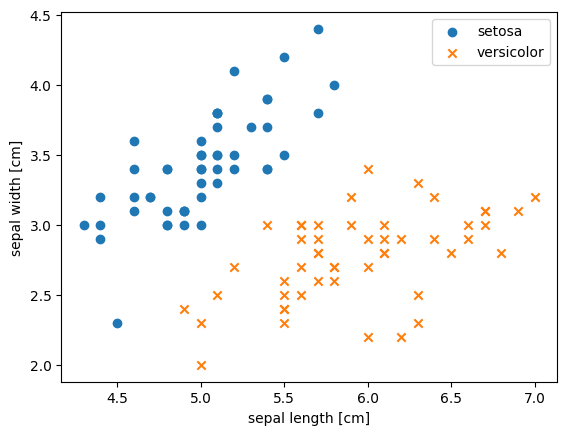

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Carregar o dataset Iris
df = pd.read_csv(
    'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data',
    header=None
)

# Selecionar Setosa e Versicolor
y = df.iloc[0:100, 4].values

# Converter as classes para -1 e 1
y = np.where(y == 'Iris-setosa', -1, 1)

# Utilizar as duas primeiras colunas como features
X = df.iloc[0:100, [0, 1]].values

# Visualizar os dados
plt.scatter(
    X[:50, 0],
    X[:50, 1],
    marker='o',
    label='setosa'
)

plt.scatter(
    X[50:100, 0],
    X[50:100, 1],
    marker='x',
    label='versicolor'
)

plt.xlabel('sepal length [cm]')
plt.ylabel('sepal width [cm]')
plt.legend()
plt.show()

In [13]:
ppn = Perceptron(eta=0.001, n_iter=50)

ppn.fit(X, y)

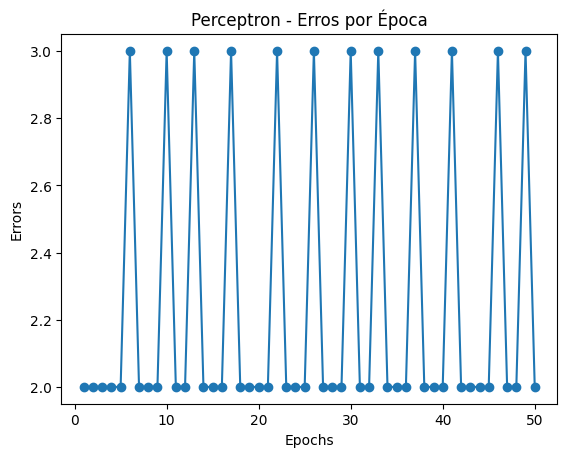

In [14]:
plt.plot(
    range(1, len(ppn.errors_) + 1),
    ppn.errors_,
    marker='o'
)

plt.xlabel('Epochs')
plt.ylabel('Errors')
plt.title('Perceptron - Erros por Época')
plt.show()

In [15]:
from sklearn.metrics import accuracy_score

y_pred = ppn.predict(X)

accuracy = accuracy_score(y, y_pred)

print(f'Acurácia do Perceptron: {accuracy:.4f}')

Acurácia do Perceptron: 0.8500


Ao utilizar as duas primeiras características do Iris, o comportamento do Perceptron pode ser diferente daquele obtido utilizando sepal length e petal length.

A separação entre setosa e versicolor utilizando comprimento e largura da sépala ainda apresenta uma região de separação razoável, porém existe maior sobreposição entre as classes do que quando utilizamos algumas combinações envolvendo o comprimento da pétala.

# Exercício 3

Perceptron

O Perceptron utiliza uma função degrau para determinar a classe:

$$ \hat{y} = \begin{cases} 1, & z \geq 0\\ -1, & z < 0 \end{cases} $$

Durante o treinamento, compara diretamente a classe real com a classe prevista.

Adaline

O Adaline utiliza uma função de ativação linear:

$$ \phi(z)=z $$

Durante o treinamento, ele calcula o erro entre o valor real e a saída contínua da função linear.

O treinamento busca minimizar uma função de custo baseada no erro quadrático utilizando Gradient Descent.


# Exercício 4

In [31]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Carregar o Iris
iris = load_iris()

# Usar as duas primeiras características
X = iris.data[:, [0, 1]]
y = iris.target

# Usar apenas duas classes: Setosa e Versicolor
X = X[:100]
y = y[:100]

# Converter os rótulos para -1 e 1
y = np.where(y == 0, -1, 1)

# Dividir os dados
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)


# =========================
# PERCEPTRON
# =========================

etas = [0.0001, 0.001, 0.01, 0.05, 0.1]
n_iters = [10, 25, 50, 100, 200]

melhor_acc = 0
melhor_eta = 0
melhor_n_iter = 0

for eta in etas:
    for n_iter in n_iters:

        modelo = Perceptron(
            eta=eta,
            n_iter=n_iter
        )

        modelo.fit(X_train, y_train)

        y_pred = modelo.predict(X_test)

        acc = accuracy_score(y_test, y_pred)

        if acc > melhor_acc:
            melhor_acc = acc
            melhor_eta = eta
            melhor_n_iter = n_iter


# =========================
# ADALINE
# =========================

# Padronização dos dados
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

etas_ada = [0.0001, 0.001, 0.005, 0.01, 0.05]
n_iters_ada = [10, 25, 50, 100, 200]

melhor_acc_ada = 0
melhor_eta_ada = 0
melhor_n_iter_ada = 0

for eta in etas_ada:
    for n_iter in n_iters_ada:

        modelo = AdalineGD(
            eta=eta,
            n_iter=n_iter
        )

        modelo.fit(X_train_std, y_train)

        y_pred = modelo.predict(X_test_std)

        acc = accuracy_score(y_test, y_pred)

        if acc > melhor_acc_ada:
            melhor_acc_ada = acc
            melhor_eta_ada = eta
            melhor_n_iter_ada = n_iter


# =========================
# RESULTADO
# =========================

print("===== MELHORES RESULTADOS =====")

print("\nPerceptron:")
print("Taxa de aprendizagem:", melhor_eta)
print("Número de iterações:", melhor_n_iter)
print("Acurácia:", f"{melhor_acc:.4f}")

print("\nAdaline:")
print("Taxa de aprendizagem:", melhor_eta_ada)
print("Número de iterações:", melhor_n_iter_ada)
print("Acurácia:", f"{melhor_acc_ada:.4f}")

print("\n===== COMPARAÇÃO =====")

print("Perceptron:", f"{melhor_acc:.4f}")
print("Adaline:   ", f"{melhor_acc_ada:.4f}")

if melhor_acc > melhor_acc_ada:
    print("O Perceptron apresentou a melhor acurácia.")

elif melhor_acc_ada > melhor_acc:
    print("O Adaline apresentou a melhor acurácia.")

else:
    print("Os dois algoritmos apresentaram a mesma acurácia.")

===== MELHORES RESULTADOS =====

Perceptron:
Taxa de aprendizagem: 0.0001
Número de iterações: 10
Acurácia: 1.0000

Adaline:
Taxa de aprendizagem: 0.0001
Número de iterações: 10
Acurácia: 1.0000

===== COMPARAÇÃO =====
Perceptron: 1.0000
Adaline:    1.0000
Os dois algoritmos apresentaram a mesma acurácia.


Após testar diferentes valores de taxa de aprendizagem e número de iterações, foi possível observar que tanto o Perceptron quanto o Adaline apresentaram uma acurácia de 100% no conjunto de teste. A melhor configuração encontrada para os dois algoritmos foi uma taxa de aprendizagem de 0,0001 e 10 iterações.

Dessa forma, neste conjunto de dados, os dois algoritmos apresentaram o mesmo desempenho, classificando corretamente todas as amostras utilizadas no teste. Isso demonstra que, para esse problema específico, ambos foram capazes de realizar a classificação de forma eficiente.


### Exercício 5

In [42]:
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score

In [43]:
def avaliar_modelos(cluster_std):

    # =========================
    # CRIAÇÃO DOS DADOS
    # =========================

    X, y = make_blobs(
        n_samples=1000,
        n_features=2,
        centers=2,
        cluster_std=cluster_std,
        random_state=42
    )

    # Converter 0 e 1 para -1 e 1
    y = np.where(y == 0, -1, 1)

    # Divisão 70% treino e 30% teste
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.3,
        random_state=42,
        stratify=y
    )

    # =========================
    # PERCEPTRON
    # =========================

    ppn = Perceptron(
        eta=0.001,
        n_iter=50
    )

    ppn.fit(X_train, y_train)

    y_pred_ppn = ppn.predict(X_test)

    precision_ppn = precision_score(
        y_test,
        y_pred_ppn,
        pos_label=1,
        zero_division=0
    )

    recall_ppn = recall_score(
        y_test,
        y_pred_ppn,
        pos_label=1,
        zero_division=0
    )

    accuracy_ppn = accuracy_score(
        y_test,
        y_pred_ppn
    )

    f1_ppn = f1_score(
        y_test,
        y_pred_ppn,
        pos_label=1,
        zero_division=0
    )

    # =========================
    # ADALINE
    # =========================

    scaler = StandardScaler()

    X_train_std = scaler.fit_transform(X_train)
    X_test_std = scaler.transform(X_test)

    ada = AdalineGD(
        eta=0.001,
        n_iter=50
    )

    ada.fit(X_train_std, y_train)

    y_pred_ada = ada.predict(X_test_std)

    precision_ada = precision_score(
        y_test,
        y_pred_ada,
        pos_label=1,
        zero_division=0
    )

    recall_ada = recall_score(
        y_test,
        y_pred_ada,
        pos_label=1,
        zero_division=0
    )

    accuracy_ada = accuracy_score(
        y_test,
        y_pred_ada
    )

    f1_ada = f1_score(
        y_test,
        y_pred_ada,
        pos_label=1,
        zero_division=0
    )

    # =========================
    # RETORNO DOS RESULTADOS
    # =========================

    return {
        "cluster_std": cluster_std,

        "Perceptron_Precision": precision_ppn,
        "Perceptron_Recall": recall_ppn,
        "Perceptron_Accuracy": accuracy_ppn,
        "Perceptron_F1": f1_ppn,

        "Adaline_Precision": precision_ada,
        "Adaline_Recall": recall_ada,
        "Adaline_Accuracy": accuracy_ada,
        "Adaline_F1": f1_ada
    }

In [44]:
resultado_06 = avaliar_modelos(0.6)
resultado_08 = avaliar_modelos(0.8)

resultados = pd.DataFrame([
    resultado_06,
    resultado_08
])

resultados

,cluster_std,Perceptron_Precision,Perceptron_Recall,Perceptron_Accuracy,Perceptron_F1,Adaline_Precision,Adaline_Recall,Adaline_Accuracy,Adaline_F1
0,0.6,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,0.8,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


No exercício utilizando o conjunto de dados gerado com a função make_blobs, foram utilizados 1000 exemplos, divididos em 70% para treinamento e 30% para teste. Foram avaliados os valores de cluster_std iguais a 0,6 e 0,8.

Os resultados mostraram que tanto o Perceptron quanto o Adaline apresentaram 100% de precisão, recall, acurácia e F1-score** nos dois valores de cluster_std analisados.

Dessa forma, não foi possível identificar um algoritmo superior ao outro, pois ambos apresentaram o mesmo desempenho. Isso indica que, para esse conjunto de dados, os dois modelos conseguiram separar corretamente as classes, mesmo com o aumento da dispersão dos dados de 0,6 para 0,8.

Portanto, considerando os resultados obtidos, Perceptron e Adaline tiveram desempenho equivalente, alcançando 100% de acurácia nas duas situações analisadas.
